# Implementing a Convolutional Neural Network for Image Analysis

## About this Project

In this project, you will use [PyTorch](https://pytorch.org/) (and [TensorFlow](https://www.tensorflow.org/)) to implement a simple Convolutional Neural Network (CNN) that can recognize digits.

### Evaluation

**This project must be successfully completed and submitted in order to receive credit for this course. Your score on this project will be included in your final grade calculation.**
    
You are expected to write code where you see `# YOUR CODE HERE` within the cells of this notebook. Not all cells will be graded; code input cells followed by cells marked with `# Auto-graded test cell` will be graded. Upon submitting your work, the code you write at these designated positions will be assessed using an "auto-grader" that will run all test cells to assess your code. You will receive feedback from the auto-grader that will identify any errors in your code. Use this feedback to improve your code if you need to resubmit. Be sure not to change the names of any provided functions, classes, or variables within the existing code cells, as this will interfere with the auto-grader. Also, remember to execute all code cells sequentially, not just those you’ve edited, to ensure your code runs properly.
    
You can resubmit your work as many times as necessary before the submission deadline. If you experience difficulty or have questions about this exercise, use the Q&A discussion board to engage with your peers or seek assistance from the instructor.

Before starting your work, please review [eCornell's policy regarding plagiarism](https://s3.amazonaws.com/ecornell/global/eCornellPlagiarismPolicy.pdf) (the presentation of someone else's work as your own without source credit).

### Submit Code for Auto-Grader Feedback

Once you have completed your work on this notebook, you will submit your code for auto-grader review. Follow these steps:

1. **Save your notebook.**

2. **Mark as Completed** — In the blue menu bar along the top of this code exercise window, you’ll see a menu item called **Education**. In the **Education** menu, click **Mark as Completed** to submit your code for auto-grader/instructor review. This process will take a moment and a progress bar will show you the status of your submission.

3. **Review your results** — Once your work is marked as complete, the results of the auto-grader will automatically be presented in a new tab within the code exercise window. You can click on the assessment name in this feedback window to see more details regarding specific feedback/errors in your code submission.

4. **Repeat, if necessary** — The Jupyter notebook will always remain accessible in the first tabbed window of the exercise. To reattempt the work, you will first need to click **Mark as Uncompleted** in the **Education** menu and then proceed to make edits to the notebook. Once you are ready to resubmit, follow steps one through three. You can repeat this procedure as many times as necessary.

You can also download a copy of this notebook in multiple formats using the **Save and Export Notebook As** option in the **File** menu above.

## Getting Started

### Python Initialization

Please run all the code cells in this section to properly initialize your Python kernel. You should be running a version of Python 3.x.

In [1]:
%load_ext autoreload

In [2]:
%%capture
from tqdm.notebook import tqdm
tqdm().pandas()

In [3]:
%autoreload 2

import math
import numpy as np

# Non-interactive matplotlib plots
%matplotlib inline
import matplotlib.pyplot as plt

# PyTorch and submodules
import torch
import torch.nn as nn
from torch.nn import functional as F
from torchvision import datasets, transforms
import torchvision

# TensorFlow (suppress messages and allocate GPU memory)
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"              # Suppress messages
os.environ["TF_GPU_ALLOCATOR"] = "cuda_malloc_async"  # Allocate GPU memory
import tensorflow as tf

import sys
sys.path.append("/home/codio/workspace/.modules")
from helper import *

The next cell checks the version of Python, PyTorch+CUDA, and TensorFlow. It also reports whether PyTorch and TensorFlow are using the GPU or only the CPU.

**NOTE:** If the GPU is being used, model training will be significantly faster (~20x) than using the CPU alone.

In [4]:
print("Python version:", sys.version.split(" ")[0])
print("PyTorch+CUDA version:", torch.__version__)
print("TensorFlow version:", tf.__version__)
print()

gpu_available_torch = torch.cuda.is_available()
if gpu_available_torch:
    print("PyTorch is using the GPU.")
    torch.cuda.manual_seed(1)  # Seed the random number generator
else:
    print("PyTorch is only using the CPU.")
    torch.manual_seed(1)  # Seed the random number generator

gpu_list = tf.config.list_physical_devices("GPU")
if len(gpu_list) > 0:
    print("TensorFlow is using the GPU.")
else:
    print("TensorFlow is only using the CPU.")

Python version: 3.12.5
PyTorch+CUDA version: 2.3.1+cu121
TensorFlow version: 2.16.2

PyTorch is using the GPU.
TensorFlow is using the GPU.


## Convolutional Neural Network

### Part One: Loading the Dataset and Setting Up Dataloader [Ungraded]

We will be using a well-known public dataset called [MNIST](https://en.wikipedia.org/wiki/MNIST_database), which consists of 60,000 training and 10,000 test black and white images of handwritten digits with labels. The MNIST data has been widely used in the Machine Learning research community to develop image processing models.

Using PyTorch, we download the dataset locally, and wrap it up in a "dataloader." The models will iterate on batches in the dataloaders.

In [5]:
# Setup the training set and test set
trainset = datasets.MNIST(
    root=".", train=True, download=True, transform=transforms.ToTensor()
)
testset = datasets.MNIST(
    root=".", train=False, download=True, transform=transforms.ToTensor()
)

# Setup dataloader that stacks small batches of images (512 per batch)
# into PyTorch Tensors for easier training and evaluation.
trainloader = torch.utils.data.DataLoader(
    trainset, shuffle=True, drop_last=True, batch_size=512, num_workers=2
)
testloader = torch.utils.data.DataLoader(
    testset, shuffle=True, drop_last=False, batch_size=512, num_workers=2
)

You can visualize a small batch of the data by running the next cell.

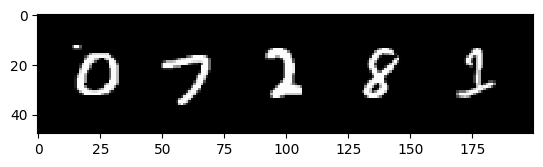

In [6]:
# The following line gets us small batch of data;
# X is a tensor of size (512, 1, 28, 28) that contains a batch of images,
# and y is a tensor of size (512) that contains the labels in X.
X, y = next(iter(trainloader))


def visualize_data(X):
    img_grid = torchvision.utils.make_grid(X[:5], padding=10)
    img_grid = img_grid.numpy()
    plt.figure()
    plt.imshow(np.transpose(img_grid, (1, 2, 0)), interpolation="nearest")
    return


visualize_data(X)

### Part Two: Define a Convolutional Neural Network [Graded]

#### Define a Building Block of a CNN

A Convolutional Neural Network (CNN) is made of multiple convolutional filters/kernels in a "block" that comprises the tunable weight parameters between a pair of layers. We create a class `Block` to hold all the parameters and define a `forward` function for forward propagation.

In [7]:
class Block(nn.Module):
    def __init__(self, in_channel, out_channel, kernel_size=3, stride=1):
        """
        Initializes a block consisting of two layers:
            1. Convolutional layer
            2. Batch normalization layer
        """
        super().__init__()

        # Define block parameters
        self.in_channel = in_channel
        self.out_channel = out_channel
        self.kernel_size = kernel_size
        self.stride = stride

        # Define convolutional layer and batch normalization layer
        self.conv = nn.Conv2d(in_channel, out_channel, kernel_size, stride)
        self.bn = nn.BatchNorm2d(out_channel)
        
        return

    def forward(self, x):
        """
        Passes the input image through a convolutional layer,
        followed by a batch normalization layer and ReLU transition.
        """
        out = F.relu(self.bn(self.conv(x)))
        return out

The next cell creates a block `Block1` that takes in an image of 1 channel and is made up of 10 filters with size 3 by 3 and stride 1. After passing the image through the block, the shape of the resulting tensor is printed.

In [8]:
Block1 = Block(1, 10, 3, 1)
out = Block1(X)
print(out.shape)

torch.Size([512, 10, 26, 26])


#### Build a CNN Using the `Block` Class [Graded]

In this section, you will build a Convolutional Neural Network in **`ConvNet`** that consists of 4 CNN blocks, an average pooling layer and a fully connected layer **in this order**. We have created the first block for you. What you need to do is create the rest of the blocks based on the specification.  

You can see that `self.block1` is initialized with `Block()`. Below it are the specs for the other 3 blocks.

In other words, your solution should be 3 lines that initialize `self.block2`, `self.block3`, and `self.block4` where it says `# TODO`. You need to pass in the appropriate parameters to `Block(input_size, num_filters, kernel_size, stride)`. Note that the `input_size` of one layer is the `num_filters` of the previous layer.

**NOTE:** Please do not change the name of the layers or else you risk breaking the auto-grader code!

In [12]:
class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()
        # First block takes in the image of channel 1.
        # Filter specification:
        # Num filters=16, kernel size 3, stride 1
        self.block1 = Block(1, 16, 3, 1)

        # TODO #1: Create second block called self.block2
        # that takes in the output of the first block.
        # Filter specification:
        # num_filters=32, kernel_size=3, stride=1
        self.block2 = Block(16, 32, 3, 1)
        # YOUR CODE HERE
        #raise NotImplementedError("Your code is missing.")
        # END OF YOUR CODE

        # TODO #2: Create third block called self.block3
        # that takes in the output of the second block.
        # Filter specification:
        # num_filters=64, kernel_size=3, stride=1
        self.block3 = Block(32, 64, 3, 1)
        # YOUR CODE HERE
     #   raise NotImplementedError("Your code is missing.")
        # END OF YOUR CODE

        # TODO #3: Create fourth block called self.block4
        # that takes in the output of the third block.
        # Filter specification:
        # num_filters=128, kernel_size=3, stride=1
        self.block4 = Block(64,128,3,1)
        # YOUR CODE HERE
       # raise NotImplementedError("Your code is missing.")
        # END OF YOUR CODE

        # This is the average pooling layer.
        # This is applied to the output of the last convolutional layer.
        # Essentially, it averages feature maps spatially to a single number.
        # For instance, if the output of the last conv layer is of size (128, 15, 4, 4),
        # then the following layer will average the 4x4 array into a single number,
        # so the output of applying this layer would have size (128, 15, 1, 1).
        # This operation vectorize the feature maps so that we can have a vector
        # that can be passed into a simple linear layer for classification.
        self.avgpool = nn.AdaptiveAvgPool2d(1)

        # Create a linear layer:
        # the dataset has 10 classes, and
        # the model should output 10 belief values.
        self.fc = nn.Linear(128, 10)

        return

    def forward(self, x):
        batch_size = x.size(0)
        out = self.block1(x)
        out = self.block2(out)
        out = self.block3(out)
        out = self.block4(out)

        # Use `.squeeze()` method to remove unnecessary dimensions of size 1.
        # For example, if `X` is of shape (128, 128, 1, 1),
        # then the shape of `X.squeeze()` would be (128, 128).
        out = self.avgpool(out).squeeze()
        out = self.fc(out)
        
        return out

The next cell creates a CNN model named `model`. If a CUDA-enabled GPU is available to PyTorch, we use `model.cuda()` to refactor the model with CUDA code that takes full advantage of the GPU during training and significantly speeds up the process.

In [13]:
# Create a CNN model
model = ConvNet()

# Equip model with CUDA code if GPU is available
if gpu_available_torch:
    model = model.cuda()

Run the next cell to check your code in the previous cell.

In [14]:
def model_test1():
    """
    Check that block2, block3, block4 are instances of Block
    """
    model = ConvNet()

    # Create CUDA model when GPU is available
    if gpu_available_torch:
        model = model.cuda()
    
    isblock2 = isinstance(model.block2, Block)
    isblock3 = isinstance(model.block3, Block)
    isblock4 = isinstance(model.block3, Block)
    
    return isblock2 and isblock3 and isblock4


def model_test2():
    """
    Check specifications for block2
    """
    model = ConvNet()

    # Create CUDA model when GPU is available
    if gpu_available_torch:
        model = model.cuda()

    # Check input channel
    in_channel_check = model.block2.in_channel == 16

    # Check output channel
    out_channel_check = model.block2.out_channel == 32

    # Check kernel size
    kernel_size_check = model.block2.kernel_size == 3

    # Check stride size
    stride_check = model.block2.stride == 1
    
    return in_channel_check and out_channel_check and kernel_size_check and stride_check


def model_test3():
    """
    Check specifications for block3
    """
    model = ConvNet()

    # Create CUDA model when GPU is available
    if gpu_available_torch:
        model = model.cuda()

    # Check input channel
    in_channel_check = model.block3.in_channel == 32

    # Check output channel
    out_channel_check = model.block3.out_channel == 64

    # Check kernel size
    kernel_size_check = model.block3.kernel_size == 3

    # Check stride size
    stride_check = model.block3.stride == 1
    
    return in_channel_check and out_channel_check and kernel_size_check and stride_check


def model_test4():
    """
    Check specifications for block4
    """
    model = ConvNet()

    # Create CUDA model when GPU is available
    if gpu_available_torch:
        model = model.cuda()

    # Check input channel
    in_channel_check = model.block4.in_channel == 64

    # Check the output channel
    out_channel_check = model.block4.out_channel == 128

    # Check the kernel size
    kernel_size_check = model.block4.kernel_size == 3

    # Check the stride size
    stride_check = model.block4.stride == 1
    
    return in_channel_check and out_channel_check and kernel_size_check and stride_check


runtest(model_test1, "model_test1")
runtest(model_test2, "model_test2")
runtest(model_test3, "model_test3")
runtest(model_test4, "model_test4")

Running Test: model_test1 ... ✔ Passed!
Running Test: model_test2 ... ✔ Passed!
Running Test: model_test3 ... ✔ Passed!
Running Test: model_test4 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (model_test1)

In [ ]:
# Auto-graded test cell worth one point (model_test2)

In [ ]:
# Auto-graded test cell worth one point (model_test3)

In [ ]:
# Auto-graded test cell worth one point (model_test4)

### Part Three: Define a Loss Function and Optimizer [Graded]

You are going to define the loss function and the optimizer. You should familiarize yourself with looking up PyTorch documentation.

#### Loss Function [Graded]

The loss function should be the **cross-entropy loss**. You can also implement the loss function yourself but we strongly suggest you use PyTorch's implementation — it should be one short call to a [library](https://pytorch.org/docs/stable/nn.html#loss-functions) loss function.

In [15]:
# TODO: Define your loss function
loss_fn = None
# YOUR CODE HERE
#loss_fn = nn.CrossEntropyLoss(weight=None, size_average=None, ignore_index=-100, reduce=None, reduction='mean', label_smoothing=0.0)[source]
loss_fn = nn.CrossEntropyLoss()
# END OF YOUR CODE

Run the next cell to check your code in the previous cell.

In [16]:
def loss_fn_test1():
    """
    Check that the loss is a scalar
    """
    num_classes = 10                                  # Number of classes
    num_examples = 5                                  # Number of examples
    logits = torch.ones((num_examples, num_classes))  # Simulate model belief
    y = torch.zeros(num_examples).long()              # Tensor of zeros
    loss = loss_fn(logits, y)                         # Calculate the loss
    return loss.size() == torch.Size([])


def loss_fn_test2():
    """
    Check that if the model has equal belief for each class (i.e., P(y|x) is uniform),
    then the negative log-likelihood should be -log(1 /num_classes) = log(num_classes).
    """
    num_classes = 10  # Number of classes
    num_examples = 1  # Number of examples

    # Simulate model belief that each class is equally likely,
    # and then calculate your loss.
    logits = torch.ones((num_examples, num_classes))
    y = torch.zeros(num_examples).long()
    loss = loss_fn(logits, y)

    return loss.item() == torch.log(torch.Tensor([num_classes])).item()


def loss_fn_test3():
    """
    Check that your loss is close to our loss
    """
    num_classes = 10  # Number of classes
    num_examples = 5  # Number of examples

    # Simulate model belief that each class is equally likely,
    # and then calculate your loss and our loss.
    logits = torch.rand((num_examples, num_classes))
    y = torch.zeros(num_examples).long()
    loss = loss_fn(logits, y)
    loss_grader = loss_fn_grader(logits, torch.zeros(num_examples).long())

    return (torch.abs(loss - loss_grader)).item() < 1e-5


runtest(loss_fn_test1, "loss_fn_test1")
runtest(loss_fn_test2, "loss_fn_test2")
runtest(loss_fn_test3, "loss_fn_test3")

Running Test: loss_fn_test1 ... ✔ Passed!
Running Test: loss_fn_test2 ... ✔ Passed!
Running Test: loss_fn_test3 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (loss_fn_test1)

In [ ]:
# Auto-graded test cell worth one point (loss_fn_test2)

In [ ]:
# Auto-graded test cell worth one point (loss_fn_test3)

#### Optimizer [Graded]

In the next cell, you will define an **SGD optimizer**. Again, you should just call one library function from [`torch.optim`](https://pytorch.org/docs/stable/optim.html). In addition to passing in the model parameters `model.parameters()`, please set `lr=0.1`.

In [18]:
# TODO: Define your optimizer
optimizer = None
# YOUR CODE HERE
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
# END OF YOUR CODE

Run the next cell to check your implementation of `optimizer`.

In [19]:
def optimizer_test1():
    """
    Check that you implemented the correct type of optimizer
    """
    return isinstance(optimizer, torch.optim.SGD)

runtest(optimizer_test1, "optimizer_test1")

Running Test: optimizer_test1 ... ✔ Passed!


Skip over the auto-graded test cell below (see [Evaluate](#Evaluate) for details).

In [ ]:
# Auto-graded test cell worth one point (optimizer_test1)

### Part Four: Train the Network [Graded]

In this section, you are going to implement the **`train`** function. Please see the `# TODO` comments in the code stub for specifications. Your solution should be one line for each TODO item (that is, 3 lines total). 

- `TODO #1:` Perform a forward pass by calling `model` on the current mini-batch `X` and store the result in `logits`

- `TODO #2:` Evaluate the loss using the loss function `loss_fn` and store the result in `loss` (look at the tests above to see how the loss function is called)

- `TODO #3:` Finally, you need to backpropagate by calling `loss.backward()`

In [28]:
def train(model, optimizer, loss_fn, trainloader):
    """
    Trains a model using the optimizer, loss function, and training data in trainloader.

    Input:
        model: ConvNet model
        optimizer: Optimizer for the model
        loss_fn: Loss function
        trainloader: Dataloader with training data

    Output:
        running_loss: Average loss of the network
    """
    model.train()       # Put the model in training mode
    running_loss = 0.0  # Keep track of the running loss

    # Iterate through trainloader; for each interation,
    # you will get a batch of images X and labels y.
    for i, (X, y) in enumerate(trainloader):

        # Move data to CUDA GPU to accelerate training
        if gpu_available_torch:
            X, y = X.cuda(), y.cuda()

        # Zero the parameter gradient
        optimizer.zero_grad()

        # TODO #1: Do a forward pass to get the logits
        logits = None
        # YOUR CODE HERE
        logits = model(X)
        # END OF YOUR CODE

        # TODO #2: Evaluate the loss
        loss = None
        # YOUR CODE HERE
        loss = loss_fn(logits, y)
        # END OF YOUR CODE

        # TODO #3: Do a backward pass using .backward()
        # YOUR CODE HERE
        loss.backward()
        
        # END OF YOUR CODE

        optimizer.step()             # Update the parameters
        running_loss += loss.item()  # Update the loss
    
    return running_loss / len(trainloader)

Run the next cell to check your code in the previous cell.

In [29]:
def train_test1():
    """
    Check that your losses are close to our losses
    """
    from copy import deepcopy

    model = ConvNet()
    if gpu_available_torch:
        model = model.cuda()
    model2 = deepcopy(model)

    optimizer = create_optimizer(model)
    optimizer2 = create_optimizer(model2)

    # Sample one batch of training examples
    X, y = next(iter(trainloader))

    # Create a dataset using the small batch
    small_set = torch.utils.data.TensorDataset(X, y)

    # Create a dataloader for the small_set
    loader = torch.utils.data.DataLoader(small_set, batch_size=128)

    # Run your train function twice (i.e., update your model twice)
    # essentially updates the model twice.
    loss = train(model, optimizer, loss_fn, loader)
    loss2 = train(model, optimizer, loss_fn, loader)

    # Run our train function twice (i.e., update our model twice)
    loss_grader = train_grader(model2, optimizer2, loss_fn, loader)
    loss_grader_2 = train_grader(model2, optimizer2, loss_fn, loader)

    return ((loss - loss_grader) ** 2 + (loss2 - loss_grader_2) ** 2) < 1e-5


runtest(train_test1, "train_test1")

Running Test: train_test1 ... ✔ Passed!


Skip over the auto-graded test cell below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (train_test1)

The following cell will train the model and should take about two minutes to run. A progress bar will display speed and duration of training.

In [30]:
num_epochs = 20
for epoch in tqdm(range(num_epochs)):
    running_loss = train(model, optimizer, loss_fn, trainloader)
    print(f"Running Loss (Epoch {epoch + 1}/{num_epochs}): {running_loss:.4f}")

  0%|          | 0/20 [00:00<?, ?it/s]

Running Loss (Epoch 1/20): 1.7661
Running Loss (Epoch 2/20): 0.9403
Running Loss (Epoch 3/20): 0.4748
Running Loss (Epoch 4/20): 0.2852
Running Loss (Epoch 5/20): 0.2072
Running Loss (Epoch 6/20): 0.1657
Running Loss (Epoch 7/20): 0.1421
Running Loss (Epoch 8/20): 0.1243
Running Loss (Epoch 9/20): 0.1114
Running Loss (Epoch 10/20): 0.1020
Running Loss (Epoch 11/20): 0.0945
Running Loss (Epoch 12/20): 0.0877
Running Loss (Epoch 13/20): 0.0815
Running Loss (Epoch 14/20): 0.0765
Running Loss (Epoch 15/20): 0.0726
Running Loss (Epoch 16/20): 0.0690
Running Loss (Epoch 17/20): 0.0662
Running Loss (Epoch 18/20): 0.0638
Running Loss (Epoch 19/20): 0.0609
Running Loss (Epoch 20/20): 0.0582


### Part Five: Test the Network on the Test Data [Graded]

In this section, you will implement **`pred`** that takes in the output of the forward pass (the `logits`) and outputs its prediction. `logits` is a matrix of shape `(n, C)` where `C` is the number of labels (10 for MNIST — number of digits). The prediction should be the `argmax` along the second axis (`dim=1`).

In [32]:
def pred(logits):
    """
    Calculates the predictions of the ConvNet using the logits.

    Input:
        logits: nxC output matrix of the network, where n is the
                number of data points and C is the number of labels

    Output:
        prediction: n-dimensional vector of predictions
    """
    # TODO: Calculate the prediction based using torch.argmax()
    # YOUR CODE HERE
    prediction = torch.argmax(logits, dim=1)
    # END OF YOUR CODE
    return prediction

Run the next cell to check your code in the previous cell.

In [33]:
def pred_test1():
    """
    Check that your predictions match the expected output
    """
    logits = torch.Tensor([[0, 1], [2, -1]])    # Generate some beliefs
    prediction = pred(logits)                   # Make your predictions
    expected_output = torch.LongTensor([1, 0])  # Expected output: [1, 0]
    return torch.equal(prediction, expected_output)


runtest(pred_test1, "pred_test1")

Running Test: pred_test1 ... ✔ Passed!


Skip over the auto-graded test cell below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (pred_test1)

We trained the model above and now we can evaluate it using your `pred` function. The following cell will use your `pred` function and evaluate the whole test set and print your model's accuracy.

In [34]:
total = 0.0
correct = 0.0
model.eval()
with torch.no_grad():
    for X, y in testloader:
        if gpu_available_torch:
            X, y = X.cuda(), y.cuda()
        logits = model(X)

        prediction = pred(logits)
        total += X.size(0)
        correct += (prediction == y).sum().item()

print(f"PyTorch Accuracy: {100 * (correct / total):.2f}%")

PyTorch Accuracy: 98.24%


Run the next cell to visualize some of the test images and see the predictions generated by the PyTorch model.

PyTorch predictions for the first five test images: [7, 2, 2, 1, 2]


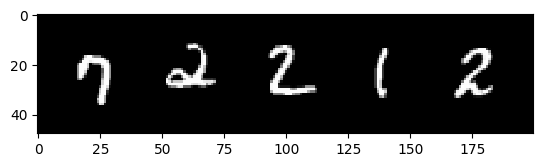

In [35]:
test_iterator = iter(testloader)
X_test, y_test = next(test_iterator)
X_test, y_test = X_test[:5], y_test[:5]
visualize_data(X_test)

model.eval()
with torch.no_grad():
    if gpu_available_torch:
        X_test = X_test.cuda()
    logits = model(X_test)
    prediction = pred(logits)

print("PyTorch predictions for the first five test images:", prediction.tolist())

## TensorFlow Approach

We can train the same network on MNIST data in Tensorflow as well.

In [36]:
def plot_imgs(images, labels=None):
    subplots_x = int(math.ceil(len(images) / 5))
    plt.figure(figsize=(10, 2 * subplots_x))
    for i in range(min(len(images), subplots_x * 5)):
        plt.subplot(subplots_x, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i], cmap=plt.cm.binary)
        if labels is not None:
            plt.xlabel(labels[i])
    plt.show()

You can view the first five images of the training set by running the cell below.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


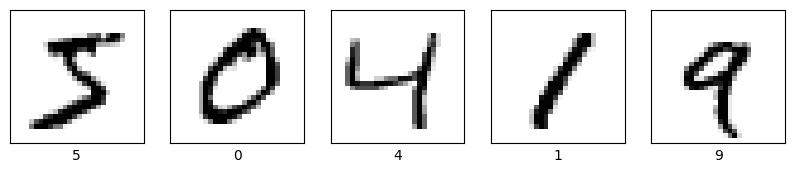

In [37]:
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()
plot_imgs(x_train[:5], y_train[:5])

Running the following cell will prepare the training and test data.

In [38]:
# TensorFlow downloads the images raw, so the
# pixel values are normalized between 0 and 1.
x_train, x_test = x_train / 255.0, x_test / 255.0

# Convert datasets of shape (num_points, 28, 28) to (num_points, 28, 28, 1)
x_train, x_test = x_train[..., np.newaxis], x_test[..., np.newaxis]

The next cell trains the model and should take a couple minutes to run.

**NOTE:** You can ignore the messages you receive when you first run the next cell.

In [39]:
def block_tf(filters, kernel_size, stride):
    return [
        tf.keras.layers.Conv2D(
            filters, kernel_size, strides=(stride, stride), activation=None
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.ReLU(),
    ]


# Define the network
model_tf = tf.keras.models.Sequential(
    [tf.keras.Input((28, 28, 1))]
    + block_tf(16, 3, 1)
    + block_tf(32, 3, 1)
    + block_tf(64, 3, 1)
    + block_tf(128, 3, 1)
    + [
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(10, activation=None),
    ]
)

model_tf.summary()

# Define the loss function and optimizer
loss_fn_tf = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
optimizer_tf = tf.keras.optimizers.SGD(learning_rate=0.1)

# Compile and fit the TensorFlow model
model_tf.compile(optimizer=optimizer_tf, loss=loss_fn_tf, metrics=["accuracy"])
model_tf.fit(x_train, y_train, epochs=5, batch_size=32);

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 26, 26, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 22, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 22, 22, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 20, 20, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,402 (388.29 KB)

 Trainable params: 98,922 (386.41 KB)

 Non-trainable params: 480 (1.88 KB)

Epoch 1/5


I0000 00:00:1787632192.525653    1845 service.cc:145] XLA service 0x76850c01ca00 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1787632192.525691    1845 service.cc:153]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5


  42/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.2791 - loss: 2.0248

I0000 00:00:1787632194.886832    1845 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8172 - loss: 0.6994
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9724 - loss: 0.1059
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9778 - loss: 0.0755
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9815 - loss: 0.0630
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9842 - loss: 0.0524


The next cell evaluates the network and shows the first five test images, along with the TensorFlow prediction below each image.

TensorFlow Accuracy: 97.32%


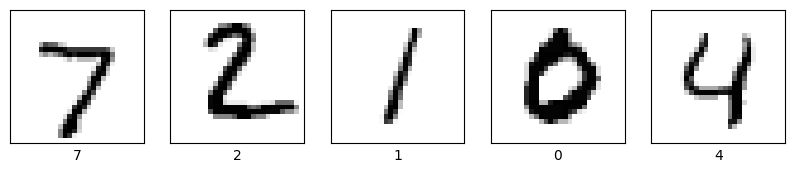

In [40]:
logits_tf = model_tf(x_test)
predictions_tf = tf.argmax(logits_tf, axis=1)
accuracy_tf = tf.reduce_mean(tf.cast(predictions_tf == y_test, tf.float64)).numpy()
print(f"TensorFlow Accuracy: {100 * accuracy_tf:.2f}%")
plot_imgs(np.squeeze(x_test * 255, axis=-1)[:5], predictions_tf.numpy()[:5])

### Visualizing Activations Using Grad-CAM

With the [Grad-CAM algorithm](https://keras.io/examples/vision/grad_cam/), we can also visualize the pixels that "trigger" activations in the convolutional layers of the network. Here's an example where the algorithm returns a heatmap of activations in the last convolutional layer triggered by the image. We superimpose the heatmap on the image, but they might not align together exactly. "Hot" (yellow-red) regions in the heatmap indicate the pixels that triggered high magnitude activations, whereas "cold" (dark blue) regions indicate the pixels that did not significantly trigger activations.

**NOTE:** The heatmap might be shifted by a few pixels.

Play around with different images and check out the activated regions. Do you think the network is triggered by regions of images that we, as humans, consider the defining features for the corresponding classes? (For example, is the network triggered by the circle of the 0 image?)

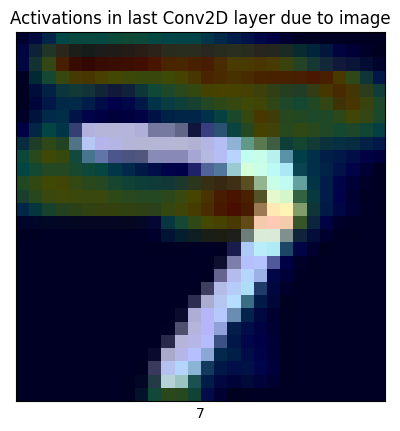

In [41]:
img_idx = 17
img_array = x_test[img_idx][np.newaxis, ...]

logits_tf2 = model_tf(img_array)
predictions_tf2 = tf.argmax(logits_tf2, axis=1)

last_conv_layer_name = [
    layer.name for layer in model_tf.layers if isinstance(layer, tf.keras.layers.Conv2D)
][-1]
heatmap = make_gradcam_heatmap(img_array, model_tf, last_conv_layer_name)
display_gradcam(
    np.uint(255 * img_array)[0], heatmap, prediction=int(predictions_tf2.numpy()[0])
)